In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
import os
import kagglehub

# 1. Download dataset dari Kaggle (otomatis mendefinisikan variabel path)
path = kagglehub.dataset_download("mkechinov/ecommerce-events-history-in-electronics-store")
print("Path to dataset files:", path)

# 2. Melihat isi folder dan membaca file CSV pertama
file_name = [f for f in os.listdir(path) if f.endswith('.csv')][0]
file_path = os.path.join(path, file_name)

print(f"Membaca file: {file_name}")
df = pd.read_csv(file_path, nrows=100000) # Membaca sampel awal 100k baris

# 3. Menampilkan informasi dasar dataset
print(df.info())
display(df.head())

100%|██████████| 20.3M/20.3M [00:00<00:00, 41.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mkechinov/ecommerce-events-history-in-electronics-store/versions/1
Membaca file: events.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     100000 non-null  object 
 1   event_type     100000 non-null  object 
 2   product_id     100000 non-null  int64  
 3   category_id    100000 non-null  int64  
 4   category_code  70426 non-null   object 
 5   brand          74110 non-null   object 
 6   price          100000 non-null  float64
 7   user_id        100000 non-null  int64  
 8   user_session   99980 non-null   object 
dtypes: float64(1), int64(3), object(5)
memory usage: 6.9+ MB
None


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2020-09-24 11:57:06 UTC,view,1996170,2144415922528452715,electronics.telephone,NaN,31.90,1515915625519388267,LJuJVLEjPT
1,2020-09-24 11:57:26 UTC,view,139905,2144415926932472027,computers.components.cooler,zalman,17.16,1515915625519380411,tdicluNnRY
2,2020-09-24 11:57:27 UTC,view,215454,2144415927158964449,NaN,NaN,9.81,1515915625513238515,4TMArHtXQy
3,2020-09-24 11:57:33 UTC,view,635807,2144415923107266682,computers.peripherals.printer,pantum,113.81,1515915625519014356,aGFYrNgC08
4,2020-09-24 11:57:36 UTC,view,3658723,2144415921169498184,NaN,cameronsino,15.87,1515915625510743344,aa4mmk0kwQ


In [3]:
df = df.drop_duplicates()

In [4]:
# missing values pada kolom kategori dan brand
df['brand'] = df['brand'].fillna('Unknown')
df['category_code'] = df['category_code'].fillna('Unknown')

In [5]:
# Memfilter anomali harga (harga harus > 0)
df = df[df['price'] > 0]

In [6]:
# Transformasi Kolom Waktu (Datetime)
df['event_time'] = pd.to_datetime(df['event_time'])
df['date'] = df['event_time'].dt.date
df['hour'] = df['event_time'].dt.hour
df['day_of_week'] = df['event_time'].dt.day_name()

print("Jumlah data setelah dibersihkan:", df.shape)

Jumlah data setelah dibersihkan: (99929, 12)


In [7]:
funnel_counts = df['event_type'].value_counts()
print("\nDistribusi Tipe Event (Sales Funnel):")
print(funnel_counts)


Distribusi Tipe Event (Sales Funnel):
event_type
view        90694
cart         5380
purchase     3855
Name: count, dtype: int64


/tmp/ipykernel_1453/917557832.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=funnel_counts.index, y=funnel_counts.values, palette='Blues_r')


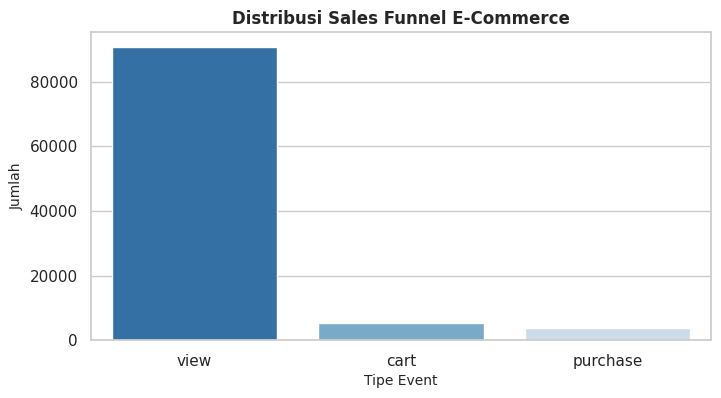

In [8]:
# Sales Funnel
plt.figure(figsize=(8, 4))
sns.barplot(x=funnel_counts.index, y=funnel_counts.values, palette='Blues_r')
plt.title('Distribusi Sales Funnel E-Commerce', fontsize=12, fontweight='bold')
plt.xlabel('Tipe Event', fontsize=10)
plt.ylabel('Jumlah', fontsize=10)
plt.show()

/tmp/ipykernel_1453/37927510.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='hour', data=df, palette='viridis')


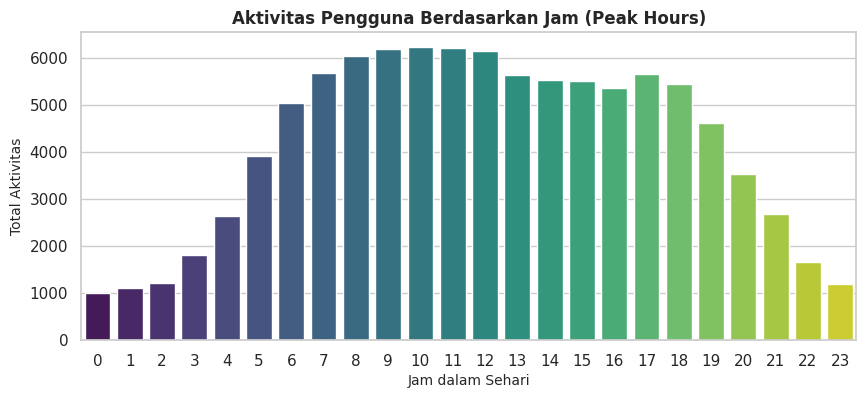

In [9]:
# 4. Analisis Pola Waktu Transaksi (Peak Hours)
plt.figure(figsize=(10, 4))
sns.countplot(x='hour', data=df, palette='viridis')
plt.title('Aktivitas Pengguna Berdasarkan Jam (Peak Hours)', fontsize=12, fontweight='bold')
plt.xlabel('Jam dalam Sehari', fontsize=10)
plt.ylabel('Total Aktivitas', fontsize=10)
plt.show()


Top 10 Kategori Produk:
category_code
Unknown                             29552
electronics.telephone               10504
computers.peripherals.printer        5996
stationery.cartrige                  5481
computers.components.cpu             3509
electronics.audio.acoustic           3258
computers.notebook                   3202
computers.components.videocards      3132
computers.components.motherboard     3046
electronics.tablet                   2165
Name: count, dtype: int64


/tmp/ipykernel_1453/408046141.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_categories.index, x=top_categories.values, palette='mako')


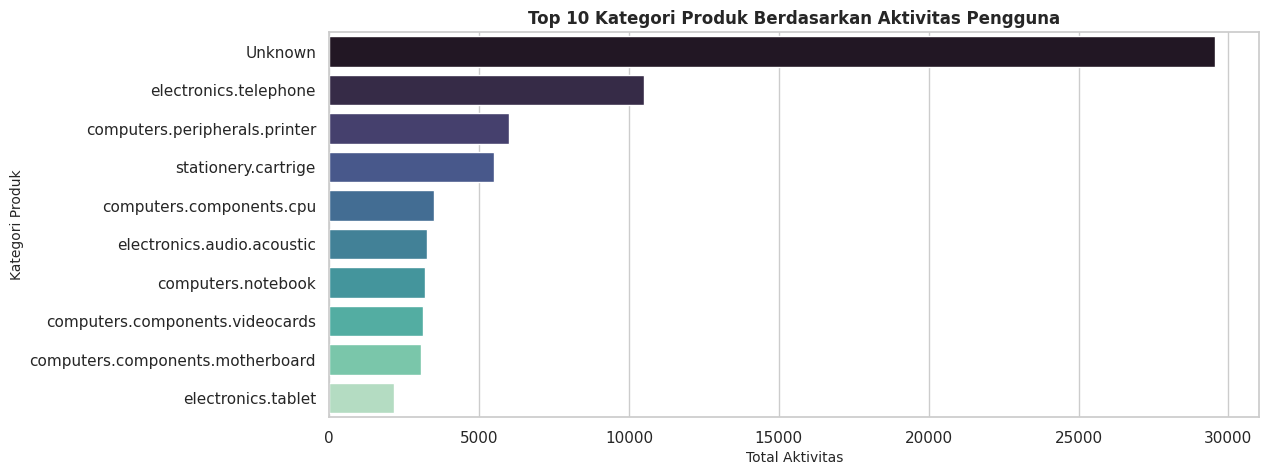

In [10]:
# Melihat 10 kategori produk yang paling sering dilihat/berinteraksi
top_categories = df['category_code'].value_counts().head(10)
print("\nTop 10 Kategori Produk:")
print(top_categories)

plt.figure(figsize=(12, 5))
sns.barplot(y=top_categories.index, x=top_categories.values, palette='mako')
plt.title('Top 10 Kategori Produk Berdasarkan Aktivitas Pengguna', fontsize=12, fontweight='bold')
plt.xlabel('Total Aktivitas', fontsize=10)
plt.ylabel('Kategori Produk', fontsize=10)
plt.show()


Rata-rata Harga Produk per Event Type:
event_type
cart        101.661188
purchase     93.567772
view        116.899777
Name: price, dtype: float64


/tmp/ipykernel_1453/763791723.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='event_type', y='price', data=df, palette='Set3')


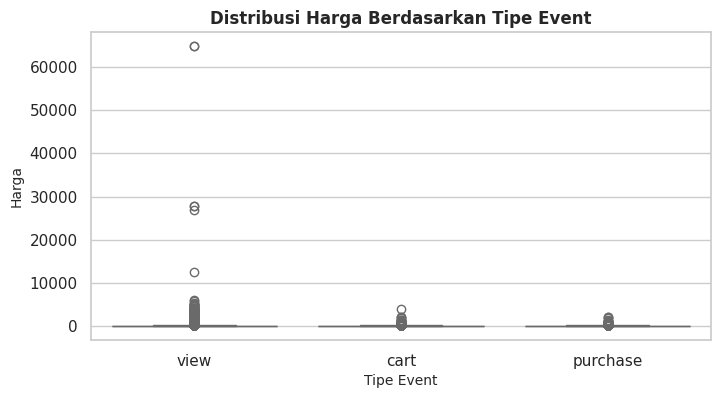

In [11]:
# Melihat rata-rata harga produk pada setiap tahapan event (view vs cart vs purchase)
avg_price_per_event = df.groupby('event_type')['price'].mean()
print("\nRata-rata Harga Produk per Event Type:")
print(avg_price_per_event)

plt.figure(figsize=(8, 4))
sns.boxplot(x='event_type', y='price', data=df, palette='Set3')
plt.title('Distribusi Harga Berdasarkan Tipe Event', fontsize=12, fontweight='bold')
plt.xlabel('Tipe Event', fontsize=10)
plt.ylabel('Harga', fontsize=10)
plt.show()

/tmp/ipykernel_1453/1333914633.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='day_of_week', data=df, order=order_days, palette='crest')


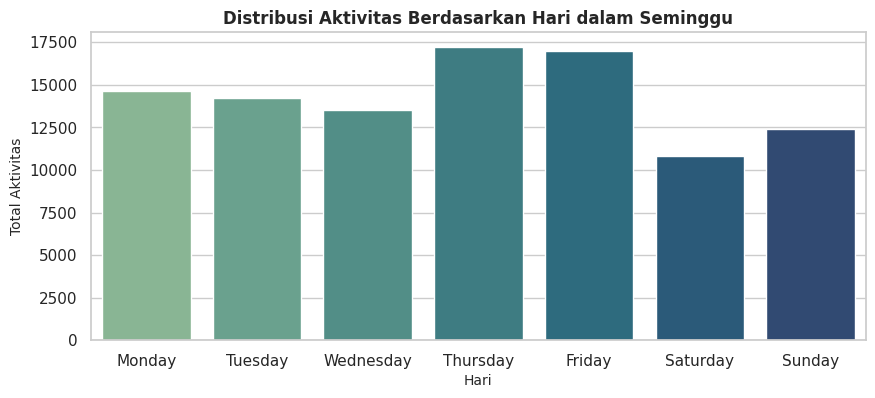

In [12]:
# Mengetahui hari dengan aktivitas transaksi paling tinggi
order_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 4))
sns.countplot(x='day_of_week', data=df, order=order_days, palette='crest')
plt.title('Distribusi Aktivitas Berdasarkan Hari dalam Seminggu', fontsize=12, fontweight='bold')
plt.xlabel('Hari', fontsize=10)
plt.ylabel('Total Aktivitas', fontsize=10)
plt.show()

In [13]:
# Menghitung persentase conversion rate dari View ke Cart, dan dari Cart ke Purchase
total_views = funnel_counts.get('view', 0)
total_carts = funnel_counts.get('cart', 0)
total_purchases = funnel_counts.get('purchase', 0)

if total_views > 0:
    view_to_cart_rate = (total_carts / total_views) * 100
    cart_to_purchase_rate = (total_purchases / total_carts) * 100 if total_carts > 0 else 0
    overall_conversion = (total_purchases / total_views) * 100

    print(f"Conversion Rate (View -> Cart): {view_to_cart_rate:.2f}%")
    print(f"Conversion Rate (Cart -> Purchase): {cart_to_purchase_rate:.2f}%")
    print(f"Overall Conversion Rate (View -> Purchase): {overall_conversion:.2f}%")

Conversion Rate (View -> Cart): 5.93%
Conversion Rate (Cart -> Purchase): 71.65%
Overall Conversion Rate (View -> Purchase): 4.25%



Top 10 Brand Berdasarkan Pembelian (Purchase):
brand
Unknown     1012
amd          165
canon        143
asus         120
sirius       101
gigabyte      93
hp            88
samsung       73
topon         73
nv-print      67
Name: count, dtype: int64


/tmp/ipykernel_1453/2501756697.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_purchased_brands.index, x=top_purchased_brands.values, palette='crest')


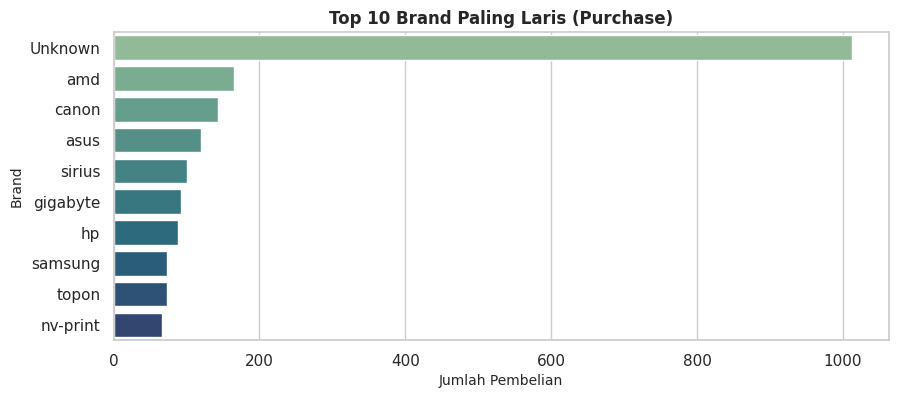

In [14]:
# Melihat brand elektronik apa saja yang paling mendominasi transaksi pembelian (purchase)
top_purchased_brands = df[df['event_type'] == 'purchase']['brand'].value_counts().head(10)
print("\nTop 10 Brand Berdasarkan Pembelian (Purchase):")
print(top_purchased_brands)

plt.figure(figsize=(10, 4))
sns.barplot(y=top_purchased_brands.index, x=top_purchased_brands.values, palette='crest')
plt.title('Top 10 Brand Paling Laris (Purchase)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Pembelian', fontsize=10)
plt.ylabel('Brand', fontsize=10)
plt.show()

In [15]:
from google.colab import drive
drive.mount('/content/drive')

target_dir = '/content/drive/MyDrive/PROJECT DATA ANALITICS/THT EXAM/Dataset'
os.makedirs(target_dir, exist_ok=True)

output_file_path = os.path.join(target_dir, 'cleaned_ecommerce_events.csv')
df.to_csv(output_file_path, index=False)

print(f"File berhasil disimpan di: {output_file_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File berhasil disimpan di: /content/drive/MyDrive/PROJECT DATA ANALITICS/THT EXAM/Dataset/cleaned_ecommerce_events.csv
